In [95]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *

![](https://editor.analyticsvidhya.com/uploads/51518iris%20img1.png)

In [96]:
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

print(X)
print(y)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [97]:
feature_names = iris.feature_names
target_names = iris.target_names
classes = np.unique(y)

print(feature_names)
print(target_names)
print(classes)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
[0 1 2]


In [98]:
print(X.shape)
print(classes)

(150, 4)
[0 1 2]


In [99]:
import pandas as pd

df = pd.read_csv('iris.csv')
df

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [100]:
y_pd = df['variety'].to_numpy()
X_pd = df.drop(['variety'], axis=1).to_numpy()

np.all(X_pd == X), np.all(y_pd == y)

(np.True_, np.False_)

In [101]:
from sklearn.preprocessing import LabelEncoder

y_pd = LabelEncoder().fit_transform(y_pd)
np.all(y_pd == y)

np.True_

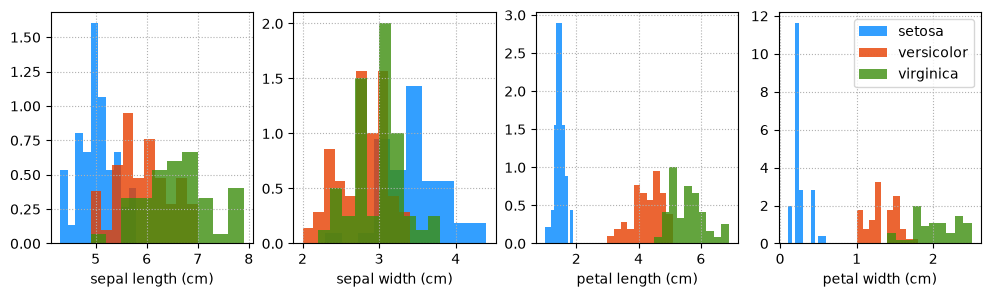

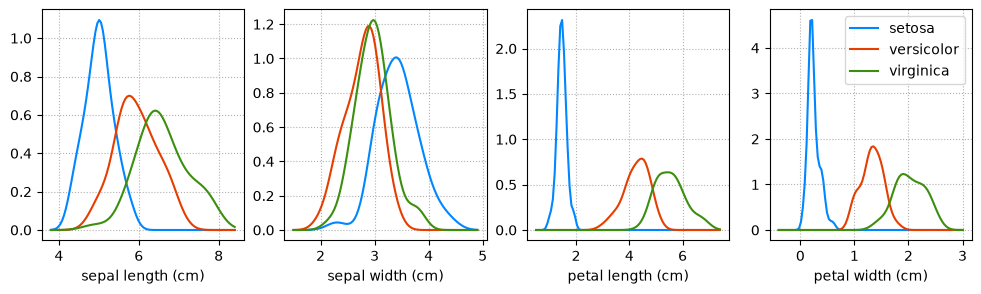

In [102]:
from utils import plot_hist, plot_kde

plot_hist(iris)
plot_kde(iris)

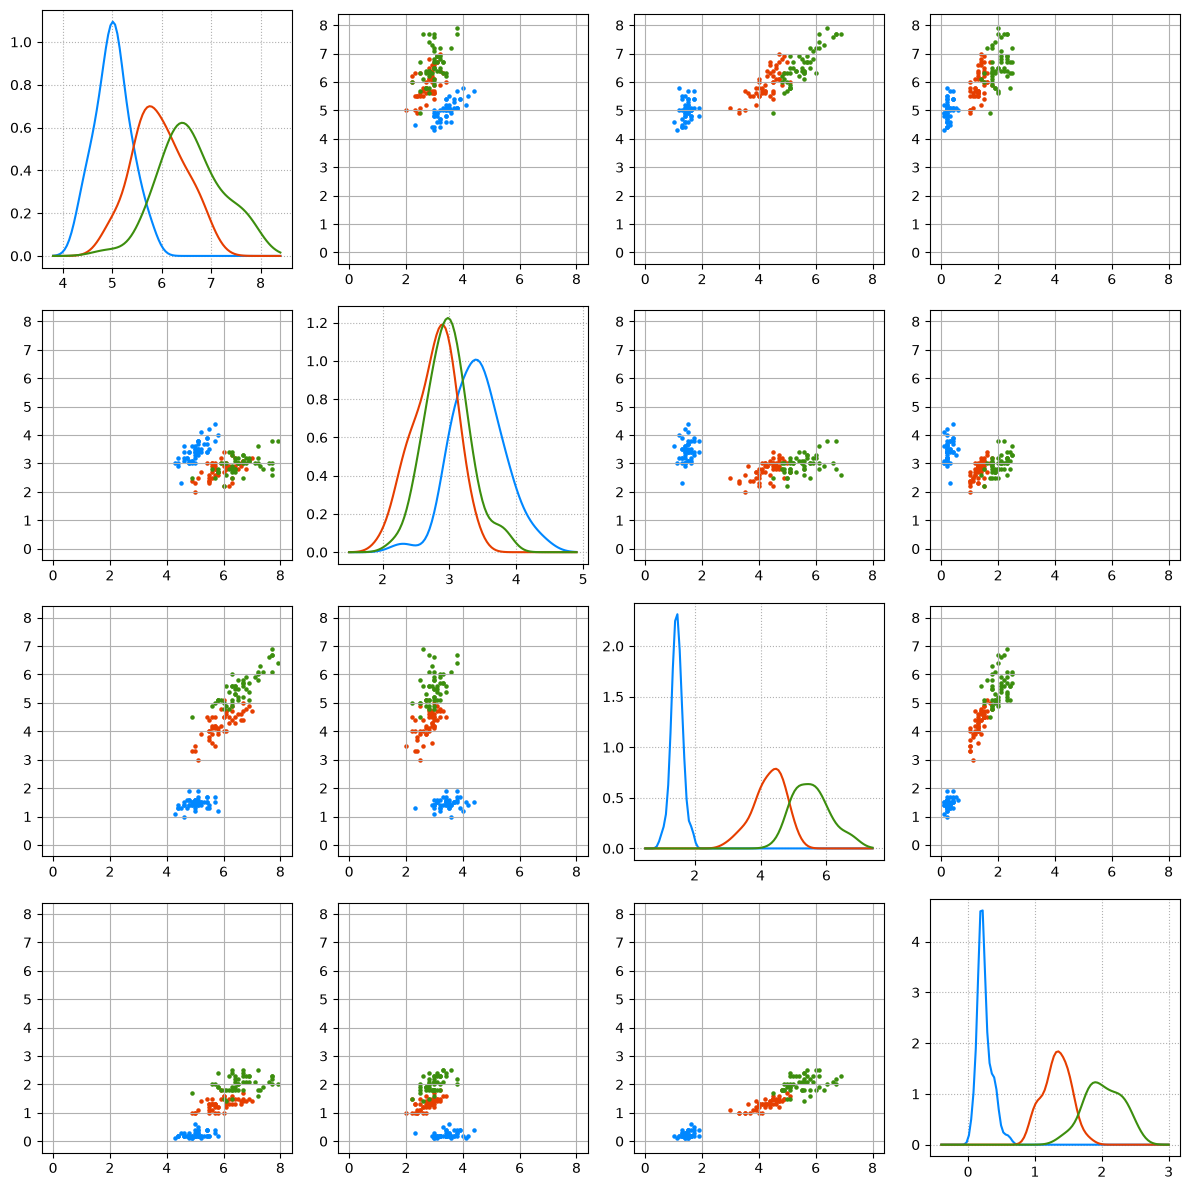

In [103]:
from utils import plot_scatter

plot_scatter(iris)

In [104]:
selected_features = (3, 2)
x = X[:, selected_features]
print(x.shape)

(150, 2)


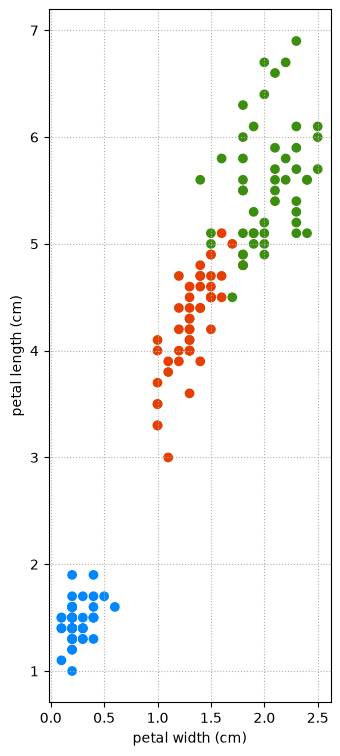

In [105]:
fig, ax = plt.subplots(1, 1, figsize=(1.5 * BW, 1.5 * BW))

ax.scatter(*x.T, c=colors[y])
ax.set_xlabel(feature_names[selected_features[0]])
ax.set_ylabel(feature_names[selected_features[1]])
ax.set_aspect(True)
ax.grid(True, ls=':')

# Algorytm Nearest Centroid

In [106]:

centroids = np.array([
    np.mean(x[y == l], axis=0) for l in classes
])

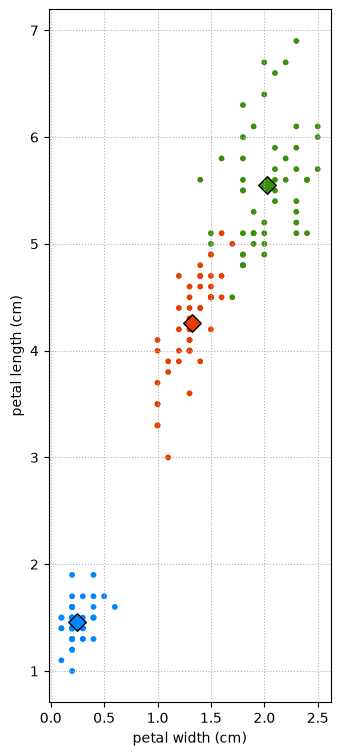

In [107]:

fig, ax = plt.subplots(1, 1, figsize=(1.5 * BW, 1.5 * BW))

ax.scatter(*x.T, c=colors[y], s=10)

for c, center in zip(colors, centroids):
    ax.scatter(*center, marker="D", s=80, facecolor=c, edgecolors='k')

ax.set_xlabel(feature_names[selected_features[0]])
ax.set_ylabel(feature_names[selected_features[1]])
ax.set_aspect('equal')
ax.grid(True, ls=':')


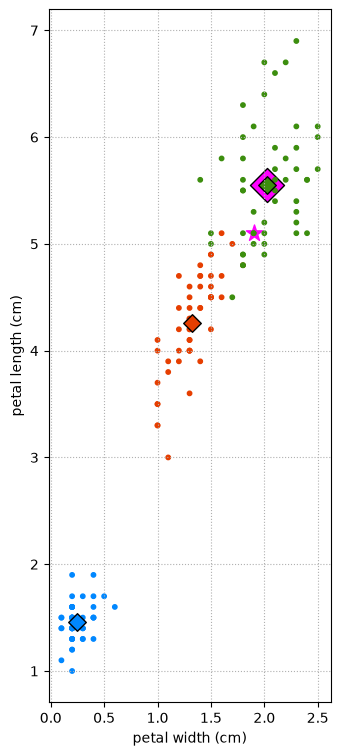

In [108]:
from scipy.spatial.distance import cdist

def nearest_centroid(X):
    dist_mat = cdist(X, centroids)
    return np.argmin(dist_mat, axis=1)

selected_i = 101
nc_i = nearest_centroid([x[selected_i]])[0]

fig, ax = plt.subplots(1, 1, figsize=(1.5 * BW, 1.5 * BW))

ax.scatter(*x[selected_i], marker='*', c='magenta', s=150)
ax.scatter(*centroids[nc_i], marker="D", s=300, facecolor='magenta', edgecolors='k')

# To juz bylo
ax.scatter(*x.T, c=colors[y], s=10)

for c, center in zip(colors, centroids):
    ax.scatter(*center, marker="D", s=80, facecolor=c, edgecolors='k')

ax.set_xlabel(feature_names[selected_features[0]])
ax.set_ylabel(feature_names[selected_features[1]])
ax.set_aspect('equal')
ax.grid(True, ls=':')

In [109]:
P = 100
# xmin, ymin = (0, 0)
# xmax, ymax = (10, 10)

xmin, ymin = np.min(x, axis=0)
xmax, ymax = np.max(x, axis=0)

xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, P),
    np.linspace(ymin, ymax, P)
)

space = np.c_[xx.ravel(), yy.ravel()]
Z = nearest_centroid(space)


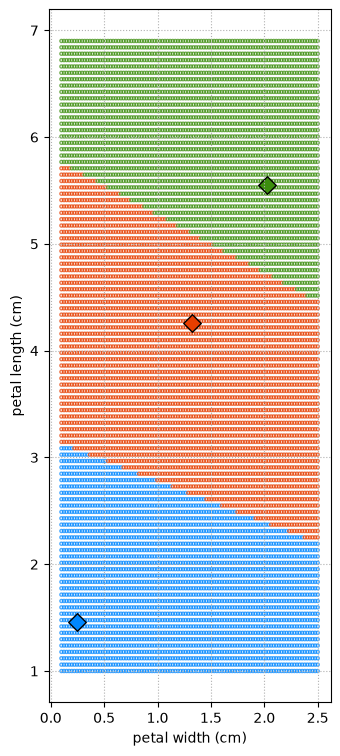

In [110]:

fig, ax = plt.subplots(1, 1, figsize=(1.5 * BW, 1.5 * BW))

# Plot space
ax.scatter(*space.T, facecolor='none', edgecolors=colors[Z], s=5, alpha=0.7)

for c, center in zip(colors, centroids):
    ax.scatter(*center, marker="D", s=80, facecolor=c, edgecolors='k')

# Plot misses
y_pred = nearest_centroid(x)
x_miss = y_pred != y
# ax.scatter(*x[x_miss].T, edgecolors='k', facecolor=colors[y[x_miss]])

ax.set_xlabel(feature_names[selected_features[0]])
ax.set_ylabel(feature_names[selected_features[1]])
ax.set_aspect('equal')
ax.grid(True, ls=':')

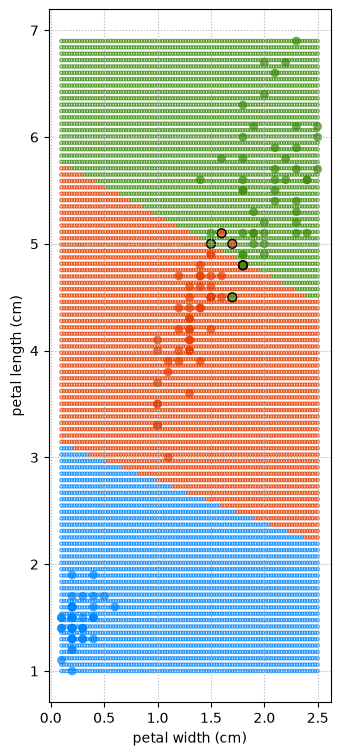

In [111]:
fig, ax = plt.subplots(1, 1, figsize=(1.5 * BW, 1.5 * BW))

# Plot space
ax.scatter(*space.T, facecolor='none', edgecolors=colors[Z], s=5, alpha=0.7)

y_pred = nearest_centroid(x)

ax.scatter(*x.T, facecolor=colors[y], edgecolors='none', s=40, alpha=0.7)


incorrect_map = (y != y_pred)
ax.scatter(*x[incorrect_map].T, c='none', edgecolors='k', s=40)

ax.set_xlabel(feature_names[selected_features[0]])
ax.set_ylabel(feature_names[selected_features[1]])
ax.set_aspect('equal')
ax.grid(True, ls=':')

In [112]:
total_samples = len(x)
x_correct = np.sum(y_pred == y)
accuracy = x_correct / total_samples

print("Example Accuracy:", accuracy)

Example Accuracy: 0.96


In [117]:
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import accuracy_score

clf = NearestCentroid()


clf = clf.fit(X, y)
y_pred = clf.predict(X)

accuracy = accuracy_score(y, y_pred)

print("Iris Accuracy:", accuracy)

clf.centroids_

Iris Accuracy: 0.9266666666666666


array([[5.006, 3.428, 1.462, 0.246],
       [5.936, 2.77 , 4.26 , 1.326],
       [6.588, 2.974, 5.552, 2.026]])

## To nie jest prawidłowy sposób weryfikacji klasyfikatora!

Ale całkiem dobry oceny trudności danych.